<a href="https://colab.research.google.com/github/AnastasyaIrsyad/ProbStat/blob/main/Probabilitas_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Mengimport Library yang dibutuhkan**

In [ ]:
import math                       # comb, perm, factorial
import itertools                  # membuat sample space (product, permutations, combinations)
from fractions import Fraction    # menampilkan peluang dalam bentuk pecahan
import numpy as np                # simulasi acak & operasi matriks
import pandas as pd               # tabel data & crosstab
import matplotlib.pyplot as plt   # grafik

np.random.seed(42)                # supaya hasil simulasi sama tiap kali dijalankan
print("Library siap dipakai")

Library siap dipakai


## Soal 1 - Gabungan, Irisan, dan Komplemen
Dari survei mahasiswa Teknik Informatika, terdapat:
* 60% menguasai Python (A)
* 45% menguasai JavaScript (B)
* 25% menguasai keduanya (A ∩ B)

**Ditanya:**

a. P(A ∪ B): menguasai minimal salah satu

b. P((A ∪ B)ᶜ): tidak menguasai keduanya

c. P(hanya Python) = P(A) − P(A ∩ B)

d. Apakah A dan B saling lepas (mutually exclusive)?

**Hitung manual**

* P(A ∪ B) = P(A) + P(B) − P(A ∩ B) = 0.60 + 0.45 − 0.25 = **0.80**
* P((A ∪ B)ᶜ) = 1 − 0.80 = **0.20**
* P(hanya Python) = 0.60 − 0.25 = **0.35**
* A ∩ B ≠ 0, jadi **tidak saling lepas**

In [ ]:
# --- Cara 1: pakai rumus ---
P_A, P_B, P_AB = 0.60, 0.45, 0.25

P_gabungan   = P_A + P_B - P_AB      # A ∪ B
P_komplemen  = 1 - P_gabungan        # tidak keduanya
P_hanya_py   = P_A - P_AB
P_hanya_js   = P_B - P_AB

print("=== Hasil Rumus ===")
print(f"P(A ∪ B)          = {P_gabungan:.2f}")
print(f"P((A ∪ B)^c)      = {P_komplemen:.2f}")
print(f"P(hanya Python)   = {P_hanya_py:.2f}")
print(f"P(hanya JS)       = {P_hanya_js:.2f}")
print("Saling lepas?     =", "Ya" if P_AB == 0 else "Tidak (ada irisan)")

=== Hasil Rumus ===
P(A ∪ B)          = 0.80
P((A ∪ B)^c)      = 0.20
P(hanya Python)   = 0.35
P(hanya JS)       = 0.20
Saling lepas?     = Tidak (ada irisan)


In [ ]:
# --- Cara 2: verifikasi dengan simulasi acak 100.000 mahasiswa ---
rng1 = np.random.default_rng(42)
n = 100_000

peluang = [0.25, 0.35, 0.20, 0.20]

# Setiap mahasiswa "diundi" masuk ke salah satu kategori
pilihan = rng1.choice(4, size=n, p=peluang)

A = (pilihan == 0) | (pilihan == 1)    # menguasai Python
B = (pilihan == 0) | (pilihan == 2)    # menguasai JavaScript

# Bandingkan hasil simulasi dengan teori
hasil = pd.DataFrame({
    "Peristiwa": ["P(A)", "P(B)", "P(A ∩ B)", "P(A ∪ B)",
                  "P((A∪B)^c)", "P(hanya Python)", "P(hanya JS)"],
    "Teori":     [0.60, 0.45, 0.25, 0.80, 0.20, 0.35, 0.20],
    "Simulasi":  [A.mean(), B.mean(), (A & B).mean(), (A | B).mean(),
                  (~(A | B)).mean(), (A & ~B).mean(), (B & ~A).mean()],
})
hasil["Selisih"] = (hasil["Simulasi"] - hasil["Teori"]).abs()

print(f"=== Simulasi {n:,} mahasiswa (acak) ===")
print(hasil.round(4).to_string(index=False))

=== Simulasi 100,000 mahasiswa (acak) ===
      Peristiwa  Teori  Simulasi  Selisih
           P(A)   0.60    0.5984   0.0016
           P(B)   0.45    0.4518   0.0018
       P(A ∩ B)   0.25    0.2495   0.0005
       P(A ∪ B)   0.80    0.8008   0.0008
     P((A∪B)^c)   0.20    0.1992   0.0008
P(hanya Python)   0.35    0.3490   0.0010
    P(hanya JS)   0.20    0.2024   0.0024


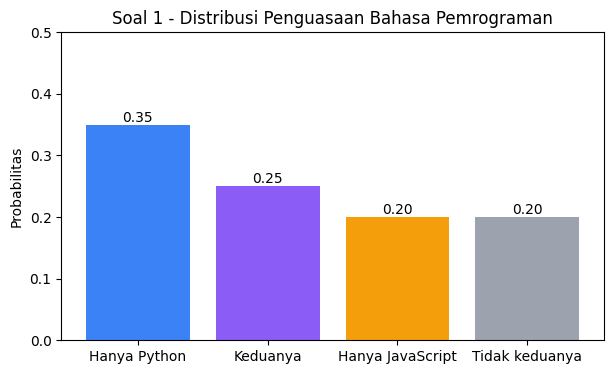

In [ ]:
# --- Visualisasi ---
label = ["Hanya Python", "Keduanya", "Hanya JavaScript", "Tidak keduanya"]
nilai = [P_hanya_py, P_AB, P_hanya_js, P_komplemen]

plt.figure(figsize=(7, 4))
bar = plt.bar(label, nilai, color=["#3b82f6", "#8b5cf6", "#f59e0b", "#9ca3af"])
plt.bar_label(bar, fmt="%.2f")
plt.title("Soal 1 - Distribusi Penguasaan Bahasa Pemrograman")
plt.ylabel("Probabilitas")
plt.ylim(0, 0.5)
plt.show()

## Soal 2 - Probabilitas Bersyarat dan Uji Independensi
Log 1000 request ke sebuah server dicatat berdasarkan **jenis request** dan **status**:

| | Sukses | Error | Total |
|---|---|---|---|
| API | 540 | 60 | 600 |
| Web | 380 | 20 | 400 |
| Total | 920 | 80 | 1000 |

**Ditanya:**

a. P(Error)

b. P(Error | API) dan P(Error | Web)

c. P(API | Error): kalau terjadi error, peluang berasal dari API

d. Apakah status error **independen** dari jenis request?

**Hitung manual**
- P(Error) = 80/1000 = **0.08**
- P(Error | API) = 60/600 = **0.10**; P(Error | Web) = 20/400 = **0.05**
- P(API | Error) = 60/80 = **0.75**
- Independen jika P(Error ∩ API) = P(Error)·P(API). Di sini 0.06 ≠ 0.08 × 0.60 = 0.048, jadi **tidak independen**

=== Tabel Kontingensi ===
status  Error  Sukses  Total
jenis                       
API        60     540    600
Web        20     380    400
Total      80     920   1000

=== Hasil Perhitungan Probabilitas ===
a. P(Error)          = 0.080
b. P(Error | API)    = 0.100
   P(Error | Web)    = 0.050
c. P(API | Error)    = 0.750

=== Tabel Probabilitas Bersyarat ===
status  Error  Sukses
jenis                
API      0.10    0.90
Web      0.05    0.95


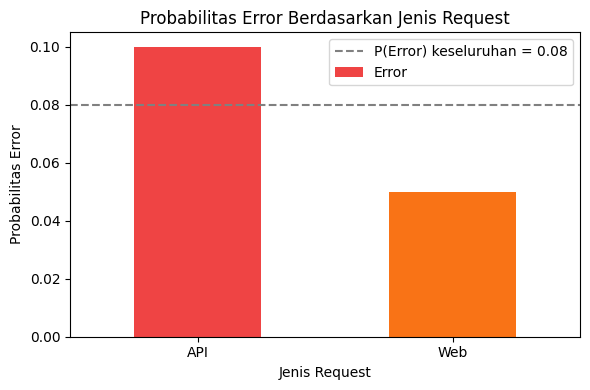


=== Uji Independensi ===
P(Error ∩ API)    = 0.060
P(Error) x P(API) = 0.048
Kesimpulan: Status Error dan jenis request TIDAK INDEPENDEN


In [ ]:
# 1. Membuat data log 1000 request
data = (
    [("API", "Sukses")] * 540 + [("API", "Error")] * 60 +
    [("Web", "Sukses")] * 380 + [("Web", "Error")] * 20
)

log = pd.DataFrame(data, columns=["jenis", "status"])

# 2. Membuat tabel kontingensi
tabel = pd.crosstab(
    log["jenis"],
    log["status"],
    margins=True,
    margins_name="Total"
)

print("=== Tabel Kontingensi ===")
print(tabel)

# 3. Menghitung jumlah seluruh data
n = len(log)

# 4. Menghitung probabilitas dasar
P_error = (log["status"] == "Error").mean()
P_api = (log["jenis"] == "API").mean()

P_error_n_api = (
    (log["status"] == "Error") &
    (log["jenis"] == "API")
).mean()

# 5. Menghitung probabilitas bersyarat
P_error_given_api = P_error_n_api / P_api

P_error_given_web = (
    log[log["jenis"] == "Web"]["status"] == "Error"
).mean()

P_api_given_error = P_error_n_api / P_error

# 6. Menampilkan hasil probabilitas
print("\n=== Hasil Perhitungan Probabilitas ===")
print(f"a. P(Error)          = {P_error:.3f}")
print(f"b. P(Error | API)    = {P_error_given_api:.3f}")
print(f"   P(Error | Web)    = {P_error_given_web:.3f}")
print(f"c. P(API | Error)    = {P_api_given_error:.3f}")

# 7. Tabel probabilitas bersyarat per baris
print("\n=== Tabel Probabilitas Bersyarat ===")

tabel_prob = pd.crosstab(
    log["jenis"],
    log["status"],
    normalize="index"
).round(3)

print(tabel_prob)

# 8. Visualisasi probabilitas Error
tabel_prob["Error"].plot(
    kind="bar",
    color=["#ef4444", "#f97316"],
    figsize=(6, 4),
    rot=0
)

# Garis pembanding probabilitas Error keseluruhan
plt.axhline(
    P_error,
    ls="--",
    color="gray",
    label=f"P(Error) keseluruhan = {P_error:.2f}"
)

plt.title("Probabilitas Error Berdasarkan Jenis Request")
plt.xlabel("Jenis Request")
plt.ylabel("Probabilitas Error")
plt.legend()
plt.tight_layout()
plt.show()

# 9. Uji independensi
P_api = (log["jenis"] == "API").mean()

print("\n=== Uji Independensi ===")
print(f"P(Error ∩ API)    = {P_error_n_api:.3f}")
print(f"P(Error) x P(API) = {P_error * P_api:.3f}")

if np.isclose(P_error_n_api, P_error * P_api):
    print("Kesimpulan: Status Error dan jenis request INDEPENDEN")
else:
    print("Kesimpulan: Status Error dan jenis request TIDAK INDEPENDEN")

## Soal 3 — Probabilitas Total dan Teorema Bayes
Sebuah antivirus memindai file di jaringan kampus.
- 2% file benar-benar **malware** → P(M) = 0.02
- Jika file malware, antivirus memberi alarm 95% → P(Alarm | M) = 0.95 *(sensitivitas)*
- Jika file aman, antivirus tetap salah alarm 4% → P(Alarm | Mᶜ) = 0.04 *(false positive)*

**Ditanya:**

a. P(Alarm): peluang antivirus berbunyi (probabilitas total)

b. P(M | Alarm): jika alarm berbunyi, peluang file itu benar-benar malware (Bayes)

c. P(M | tidak Alarm)

**Hitung manual**
- P(Alarm) = 0.02(0.95) + 0.98(0.04) = 0.019 + 0.0392 = **0.0582**
- P(M | Alarm) = 0.019 / 0.0582 = **0.3265**
- P(M | tidak Alarm) = 0.02(0.05) / (1 − 0.0582) = 0.001 / 0.9418 = **0.00106**

In [ ]:
# Menghitung Probabilitas Total dan Teorema Bayes
P_M          = 0.02    # prior malware
P_alarm_M    = 0.95    # P(Alarm | Malware)
P_alarm_aman = 0.04    # P(Alarm | Aman)

# Probabilitas total
P_alarm = P_M * P_alarm_M + (1 - P_M) * P_alarm_aman

# Teorema Bayes
P_M_given_alarm   = (P_M * P_alarm_M) / P_alarm
P_M_given_noalarm = (P_M * (1 - P_alarm_M)) / (1 - P_alarm)

print(f"P(Alarm)              = {P_alarm:.4f}")
print(f"P(Malware | Alarm)    = {P_M_given_alarm:.4f}")
print(f"P(Malware | No Alarm) = {P_M_given_noalarm:.5f}")

P(Alarm)              = 0.0582
P(Malware | Alarm)    = 0.3265
P(Malware | No Alarm) = 0.00106


In [ ]:
# Tabel Bayes
tabel_bayes = pd.DataFrame({
    "Kondisi":           ["Malware", "Aman"],
    "P(Bi)":             [P_M, 1 - P_M],
    "P(Alarm|Bi)":       [P_alarm_M, P_alarm_aman],
})
tabel_bayes["P(Bi)·P(Alarm|Bi)"] = tabel_bayes["P(Bi)"] * tabel_bayes["P(Alarm|Bi)"]
tabel_bayes["P(Bi|Alarm)"] = tabel_bayes["P(Bi)·P(Alarm|Bi)"] / tabel_bayes["P(Bi)·P(Alarm|Bi)"].sum()
print(tabel_bayes.round(4).to_string(index=False))
print(f"\nJumlah (= P(Alarm)) = {tabel_bayes['P(Bi)·P(Alarm|Bi)'].sum():.4f}")

Kondisi  P(Bi)  P(Alarm|Bi)  P(Bi)·P(Alarm|Bi)  P(Bi|Alarm)
Malware   0.02         0.95             0.0190       0.3265
   Aman   0.98         0.04             0.0392       0.6735

Jumlah (= P(Alarm)) = 0.0582


Simulasi P(Alarm)           = 0.0584
Simulasi P(Malware | Alarm) = 0.3256


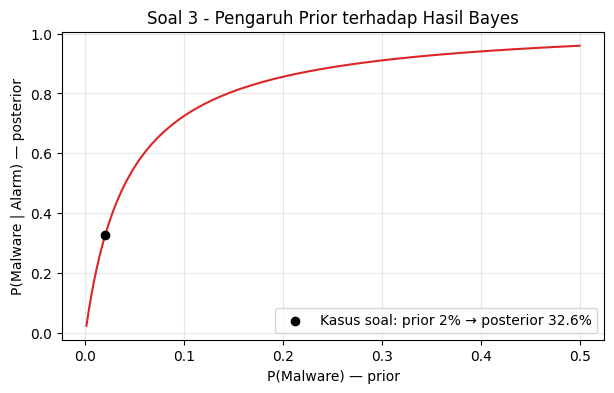

In [ ]:
# Verifikasi dengan simulasi 1.000.000 file
N = 1_000_000
is_malware = np.random.rand(N) < P_M
alarm = np.where(is_malware,
                 np.random.rand(N) < P_alarm_M,
                 np.random.rand(N) < P_alarm_aman)

print(f"Simulasi P(Alarm)           = {alarm.mean():.4f}")
print(f"Simulasi P(Malware | Alarm) = {is_malware[alarm].mean():.4f}")

# Pengaruh prior (persentase malware) terhadap posterior
prior = np.linspace(0.001, 0.5, 200)
posterior = prior * P_alarm_M / (prior * P_alarm_M + (1 - prior) * P_alarm_aman)

plt.figure(figsize=(7, 4))
plt.plot(prior, posterior, color="#dc2626")
plt.scatter([P_M], [P_M_given_alarm], color="black", zorder=3,
            label=f"Kasus soal: prior 2% → posterior {P_M_given_alarm:.1%}")
plt.xlabel("P(Malware) — prior")
plt.ylabel("P(Malware | Alarm) — posterior")
plt.title("Soal 3 - Pengaruh Prior terhadap Hasil Bayes")
plt.grid(alpha=.3); plt.legend()
plt.show()

## Soal 4 — Permutasi dan Kombinasi
a. **PIN 4 digit** (0–9), digit boleh berulang → urutan diperhatikan, dengan pengembalian: **nʳ**

b. **Kode akses 4 huruf** dari A–F, huruf tidak boleh berulang → permutasi: **n!/(n−r)!**

c. **Membentuk tim 3 orang** dari 8 developer → kombinasi: **n!/((n−r)!r!)**

d. **Memilih 3 paket library** dari 5 pilihan, paket boleh dipilih lebih dari sekali, urutan tidak penting → **C(n+r−1, r)**

e. Dari 8 developer (5 backend, 3 frontend) dipilih tim 3 orang secara acak. Berapa peluang tim berisi **tepat 2 backend dan 1 frontend**?

**Hitung manual**
- a. 10⁴ = **10.000**
- b. 6!/2! = **360**
- c. 8!/(5!·3!) = **56**
- d. C(5+3−1, 3) = C(7,3) = **35**
- e. C(5,2)·C(3,1)/C(8,3) = 10·3/56 = 30/56 = **0.5357**

In [ ]:
# --- Cara 1: pakai rumus dari modul math ---
a = 10 ** 4
b = math.perm(6, 4)
c = math.comb(8, 3)
d = math.comb(5 + 3 - 1, 3)

print("========== Hasil Rumus ==========")
print(f"a. PIN 4 digit (berulang)        = {a}")
print(f"b. Kode 4 huruf A-F (tdk ulang)  = {b}")
print(f"c. Tim 3 dari 8 developer        = {c}")
print(f"d. 3 paket dari 5 (boleh ulang)  = {d}")

# --- Cara 2: verifikasi dengan membangkitkan semua kemungkinan (itertools) ---
digit = range(10)
huruf = "ABCDEF"
dev   = ["B1", "B2", "B3", "B4", "B5", "F1", "F2", "F3"]   # B = backend, F = frontend
pkg   = ["numpy", "pandas", "scipy", "matplotlib", "seaborn"]

hasil_a = len(list(itertools.product(digit, repeat=4)))
hasil_b = len(list(itertools.permutations(huruf, 4)))
hasil_c = len(list(itertools.combinations(dev, 3)))
hasil_d = len(list(itertools.combinations_with_replacement(pkg, 3)))

print("\n========== HASIL VERIFIKASI PYTHON ==========")

print(f"a. PIN 4 digit              = {hasil_a:,} kemungkinan")
print(f"b. Kode 4 huruf             = {hasil_b} kemungkinan")
print(f"c. Tim 3 developer          = {hasil_c} kemungkinan")
print(f"d. Pilihan 3 paket library  = {hasil_d} kemungkinan")

print("\nContoh 5 kombinasi tim pertama:")
print(list(itertools.combinations(dev, 3))[:5])

========== Hasil Rumus ==========
a. PIN 4 digit (berulang)        = 10000
b. Kode 4 huruf A-F (tdk ulang)  = 360
c. Tim 3 dari 8 developer        = 56
d. 3 paket dari 5 (boleh ulang)  = 35

========== HASIL VERIFIKASI PYTHON ==========
a. PIN 4 digit              = 10,000 kemungkinan
b. Kode 4 huruf             = 360 kemungkinan
c. Tim 3 developer          = 56 kemungkinan
d. Pilihan 3 paket library  = 35 kemungkinan

Contoh 5 kombinasi tim pertama:
[('B1', 'B2', 'B3'), ('B1', 'B2', 'B4'), ('B1', 'B2', 'B5'), ('B1', 'B2', 'F1'), ('B1', 'B2', 'F2')]


========== HASIL PERHITUNGAN SOAL e ==========
Jumlah tim seluruhnya       = 56
Tim 2 backend + 1 frontend  = 30
P (rumus)                   = 0.5357  (15/28)
P (enumerasi itertools)     = 0.5357


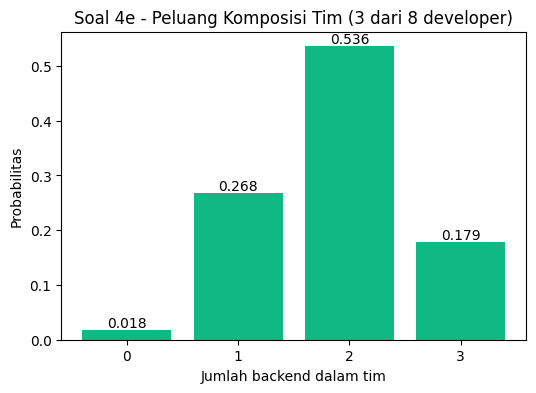

In [ ]:
# --- e. Peluang tepat 2 backend & 1 frontend ---
semua_tim = list(itertools.combinations(dev, 3))
tim_sesuai = [t for t in semua_tim
              if sum(x.startswith("B") for x in t) == 2]

P_rumus = math.comb(5, 2) * math.comb(3, 1) / math.comb(8, 3)
P_enum  = len(tim_sesuai) / len(semua_tim)

print("========== HASIL PERHITUNGAN SOAL e ==========")
print(f"Jumlah tim seluruhnya       = {len(semua_tim)}")
print(f"Tim 2 backend + 1 frontend  = {len(tim_sesuai)}")
print(f"P (rumus)                   = {P_rumus:.4f}  ({Fraction(30, 56)})")
print(f"P (enumerasi itertools)     = {P_enum:.4f}")

# Distribusi jumlah backend dalam tim
jml_backend = [sum(x.startswith("B") for x in t) for t in semua_tim]
dist = pd.Series(jml_backend).value_counts().sort_index() / len(semua_tim)

plt.figure(figsize=(6, 4))
bar = plt.bar(dist.index.astype(str), dist.values, color="#10b981")
plt.bar_label(bar, fmt="%.3f")
plt.xlabel("Jumlah backend dalam tim")
plt.ylabel("Probabilitas")
plt.title("Soal 4e - Peluang Komposisi Tim (3 dari 8 developer)")
plt.show()

## Soal 5 & 6 - Peluang

**Persiapan Library dan Fungsi Simulasi**

In [ ]:
# Fungsi bantu dipakai di Soal 5 dan Soal 6
rng = np.random.default_rng(2026)        # generator acak dengan seed tetap
DAFTAR_N = [100, 1_000, 100_000]

def definisi_2(simulator, p_teori, judul, ulang=100):
    # --- 1) frekuensi relatif berjalan ---
    kejadian = simulator(100000)
    frekuensi = np.cumsum(kejadian) / np.arange(1, 100001)
    data = []

    for n in DAFTAR_N:
        jumlah = kejadian[:n].sum()
        peluang = jumlah / n
        selisih = abs(peluang - p_teori)
        data.append([n, jumlah, peluang, selisih])

    tabel = pd.DataFrame(
        data, columns=["n", "n_a", "n_a / n", "selisih"]
    )
    print("=== Definisi 2: satu rangkaian percobaan ===")
    print(tabel.round(4).to_string(index=False))


    # --- 2) percobaan diulang berkali-kali untuk tiap n ---
    hasil_ulang = {}
    for n in DAFTAR_N:
        nilai = []
        for i in range(ulang):
            nilai.append(simulator(n).mean())

        hasil_ulang[n] = np.array(nilai)

    # Membuat tabel pengulangan
    data = []
    for n in DAFTAR_N:
        nilai = hasil_ulang[n]
        data.append([
            n,
            nilai.min(),
            nilai.max(),
            nilai.std(),
            np.sqrt(p_teori * (1 - p_teori) / n)
        ])

    tabel2 = pd.DataFrame(
        data,
        columns=["n", "min", "max", "std (simulasi)",
                 "std teori √(p(1-p)/n)"]
    )
    print(f"\n=== Definisi 2: {ulang}x pengulangan untuk tiap n ===")
    print(tabel2.round(4).to_string(index=False))

    # --- grafik ---
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    # Grafik pertama: perubahan peluang
    ax[0].semilogx(frekuensi, label="Frekuensi relatif")
    ax[0].axhline(p_teori, color="red", linestyle="--",label="Peluang teori")

    for n in DAFTAR_N:
        ax[0].scatter(n - 1, frekuensi[n - 1], color="black")

    ax[0].set_title("Frekuensi relatif mendekati nilai teori")
    ax[0].set_xlabel("Jumlah percobaan")
    ax[0].set_ylabel("Peluang")
    ax[0].legend()
    ax[0].grid()

    # Grafik kedua: sebaran 100 kali pengulangan
    for i, n in enumerate(DAFTAR_N):
        x = np.full(ulang, i) + rng.uniform(-0.15, 0.15, ulang)
        ax[1].scatter(x, hasil_ulang[n], s=12, alpha=0.6)

    ax[1].axhline(p_teori, color="red", linestyle="--",label="Peluang teori")
    ax[1].set_xticks(range(3), [str(n) for n in DAFTAR_N])
    ax[1].set_title("Sebaran 100 kali percobaan")
    ax[1].set_xlabel("Jumlah percobaan")
    ax[1].set_ylabel("Peluang")
    ax[1].legend()
    ax[1].grid()

    fig.suptitle(judul)
    plt.tight_layout()
    plt.show()

print("Fungsi bantu siap")

Fungsi bantu siap


## Soal 5 — Kode OTP 4 Digit
Sebuah aplikasi mengirim **kode OTP 4 digit** (0000–9999) yang dibuat acak; tiap digit 0–9 punya peluang sama.
Berapa peluang OTP yang dikirim **mengandung minimal satu digit 0**?

**Hitung manual (Definisi 1)**
- n = 10⁴ = 10.000 kemungkinan OTP
- OTP tanpa angka 0 = 9⁴ = 6.561
- nₐ = 10.000 − 6.561 = 3.439
- prob(A) = 3.439 / 10.000 = **0.3439**

=== Definisi 1 ===
n (semua OTP)      = 10000
n_a (ada digit 0)  = 3439
prob(A) = n_a / n  = 0.3439  (3439/10000)

=== Definisi 2: satu rangkaian percobaan ===
     n   n_a  n_a / n  selisih
   100    33   0.3300   0.0139
  1000   350   0.3500   0.0061
100000 34546   0.3455   0.0016

=== Definisi 2: 100x pengulangan untuk tiap n ===
     n    min    max  std (simulasi)  std teori √(p(1-p)/n)
   100 0.2400 0.4500          0.0453                 0.0475
  1000 0.3090 0.3830          0.0146                 0.0150
100000 0.3405 0.3478          0.0013                 0.0015


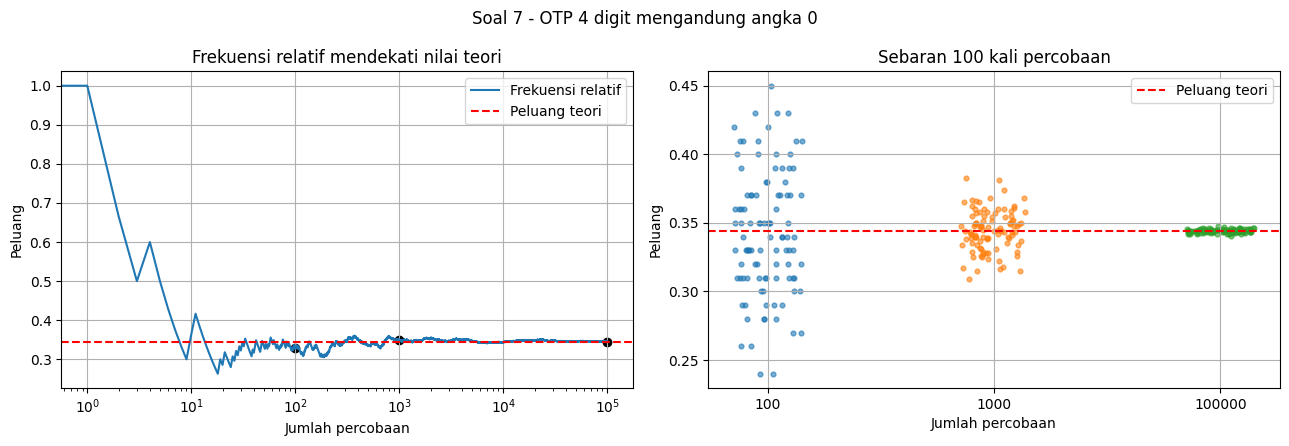

In [ ]:
# --- Definisi 1: daftar semua OTP lalu hitung n_a / n ---
ruang_sampel = list(itertools.product(range(10), repeat=4))   # (0,0,0,0) ... (9,9,9,9)
n_total = len(ruang_sampel)
n_a     = sum(1 for otp in ruang_sampel if 0 in otp)
p_otp   = n_a / n_total

print("=== Definisi 1 ===")
print(f"n (semua OTP)      = {n_total}")
print(f"n_a (ada digit 0)  = {n_a}")
print(f"prob(A) = n_a / n  = {p_otp:.4f}  ({Fraction(n_a, n_total)})\n")

# --- Definisi 2: simulasi OTP acak ---
def sim_otp(n):
    otp = rng.integers(0, 10, size=(n, 4))   # n buah OTP, masing-masing 4 digit
    return (otp == 0).any(axis=1)             # True jika ada digit 0

definisi_2(sim_otp, p_otp, "Soal 5 - OTP 4 digit mengandung angka 0")

## Soal 6 — Tabrakan Hash Table
Sebuah hash table punya **16 bucket**. Fungsi hash memetakan setiap key ke salah satu bucket secara seragam (peluang tiap bucket sama).
Jika dimasukkan **3 key**, berapa peluang terjadi **collision** (minimal 2 key masuk bucket yang sama)?

**Hitung manual (Definisi 1)**
- n = 16³ = 4.096 kemungkinan penempatan
- Penempatan tanpa tabrakan = 16 × 15 × 14 = 3.360
- nₐ = 4.096 − 3.360 = 736
- prob(A) = 736 / 4.096 = **0.1797**

=== Definisi 1 ===
n (semua penempatan) = 4096
n_a (ada collision)  = 736
prob(A) = n_a / n    = 0.1797  (23/128)

=== Definisi 2: satu rangkaian percobaan ===
     n   n_a  n_a / n  selisih
   100    24   0.2400   0.0603
  1000   192   0.1920   0.0123
100000 18014   0.1801   0.0005

=== Definisi 2: 100x pengulangan untuk tiap n ===
     n    min    max  std (simulasi)  std teori √(p(1-p)/n)
   100 0.1000 0.2800          0.0383                 0.0384
  1000 0.1490 0.2160          0.0129                 0.0121
100000 0.1773 0.1833          0.0012                 0.0012


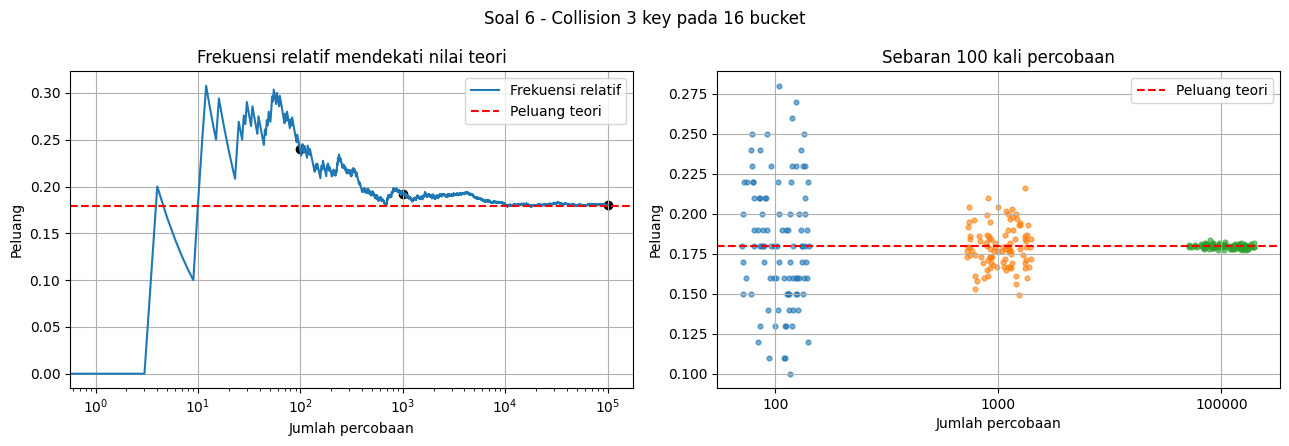

In [ ]:
# --- Definisi 1: daftar semua penempatan 3 key ke 16 bucket ---
ruang_sampel = list(itertools.product(range(16), repeat=3))
n_total = len(ruang_sampel)
n_a     = sum(1 for p in ruang_sampel if len(set(p)) < 3)   # set < 3 artinya ada bucket kembar
p_hash  = n_a / n_total

print("=== Definisi 1 ===")
print(f"n (semua penempatan) = {n_total}")
print(f"n_a (ada collision)  = {n_a}")
print(f"prob(A) = n_a / n    = {p_hash:.4f}  ({Fraction(n_a, n_total)})\n")

# --- Definisi 2: simulasi memasukkan 3 key acak ---
def sim_hash(n):
    b = rng.integers(0, 16, size=(n, 3))      # bucket untuk key-1, key-2, key-3
    return (b[:, 0] == b[:, 1]) | (b[:, 0] == b[:, 2]) | (b[:, 1] == b[:, 2])

definisi_2(sim_hash, p_hash, "Soal 6 - Collision 3 key pada 16 bucket")

## Soal 7 - Simulasi Monte Carlo: Birthday Problem
Dalam sebuah kelas berisi n mahasiswa, berapa peluang minimal 2 orang berulang tahun di hari yang sama (365 hari)? Konsep ini dipakai di TI untuk menghitung peluang tabrakan hash/ID (birthday attack).

Hitung manual (pakai komplemen) P(minimal ada yang sama) = 1 − P(semua berbeda) = 1 − (365/365 × 364/365 × … × (365−n+1)/365)

Untuk n = 30: P ≈ 0.7063

In [ ]:
def peluang_eksak(n, hari=365):
    """Rumus komplemen: 1 - P(semua ulang tahun berbeda)"""
    p_beda = 1.0
    for i in range(n):
        p_beda *= (hari - i) / hari
    return 1 - p_beda

def peluang_simulasi(n, hari=365, percobaan=20_000):
    """Monte Carlo: bangkitkan tanggal lahir acak, cek apakah ada yang kembar"""
    tanggal = np.random.randint(0, hari, size=(percobaan, n))
    tanggal.sort(axis=1)
    ada_kembar = (np.diff(tanggal, axis=1) == 0).any(axis=1)
    return ada_kembar.mean()

hasil = pd.DataFrame({"n": [10, 20, 23, 30, 40, 50, 70]})
hasil["P_eksak"]     = hasil["n"].apply(peluang_eksak)
hasil["P_simulasi"]  = hasil["n"].apply(peluang_simulasi)
hasil["selisih"]     = (hasil["P_eksak"] - hasil["P_simulasi"]).abs()
print(hasil.round(4).to_string(index=False))

 n  P_eksak  P_simulasi  selisih
10   0.1169      0.1166   0.0003
20   0.4114      0.4106   0.0008
23   0.5073      0.5138   0.0065
30   0.7063      0.7048   0.0016
40   0.8912      0.8883   0.0029
50   0.9704      0.9706   0.0002
70   0.9992      0.9992   0.0001


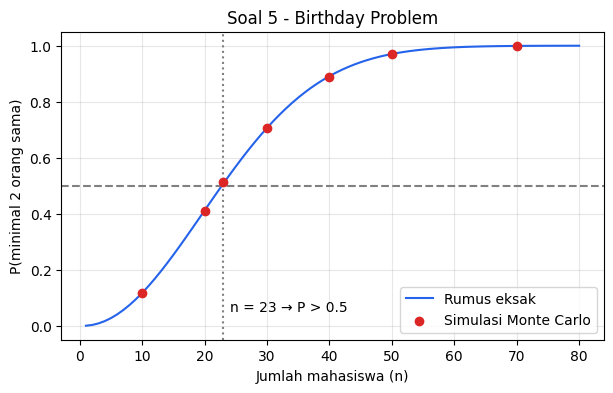

P(tabrakan ID 4-hex, 300 user) = 0.4961


In [ ]:
ns = np.arange(1, 81)
plt.figure(figsize=(7, 4))
plt.plot(ns, [peluang_eksak(k) for k in ns], label="Rumus eksak", color="#2563eb")
plt.scatter(hasil["n"], hasil["P_simulasi"], color="#dc2626", zorder=3, label="Simulasi Monte Carlo")
plt.axhline(0.5, ls="--", color="gray")
plt.axvline(23, ls=":", color="gray")
plt.text(24, 0.05, "n = 23 → P > 0.5")
plt.xlabel("Jumlah mahasiswa (n)")
plt.ylabel("P(minimal 2 orang sama)")
plt.title("Soal 5 - Birthday Problem")
plt.legend(); plt.grid(alpha=.3)
plt.show()

# Penerapan TI: tabrakan ID acak 4 digit hex (65.536 kemungkinan) untuk 300 user
print(f"P(tabrakan ID 4-hex, 300 user) = {peluang_eksak(300, 16**4):.4f}")

## Soal 8 — Probabilitas Bersyarat Berantai: Status Server Up/Down
Dari data monitoring harian (mirip contoh hari hujan di slide):
- P(Up besok | Up hari ini) = 0.90 → P(Down besok | Up hari ini) = 0.10
- P(Up besok | Down hari ini) = 0.60 → P(Down besok | Down hari ini) = 0.40

Hari ini server **Down**.

**Ditanya:**

a. Peluang server **Down 2 hari berturut-turut** berikutnya (Down → Down → Down)

b. Peluang server **Down pada hari ke-2** (lewat jalur mana pun)

c. Peluang server Up dalam jangka panjang (steady state)

**Hitung manual**
- a. P = 0.40 × 0.40 = **0.16**
- b. Jalur D→D→D + D→U→D = 0.40×0.40 + 0.60×0.10 = 0.16 + 0.06 = **0.22**
- c. π_Up = 0.60 / (0.10 + 0.60) = **0.857**

In [ ]:
# Matriks transisi: baris = kondisi hari ini, kolom = kondisi besok
P = np.array([[0.90, 0.10],    # dari Up   -> [Up, Down]
              [0.60, 0.40]])   # dari Down -> [Up, Down]
status = ["Up", "Down"]
print(pd.DataFrame(P, index=["Dari " + s for s in status], columns=["Ke " + s for s in status]))

# a. Down -> Down -> Down
p_a = P[1, 1] * P[1, 1]

# b. Down pada hari ke-2: pakai pangkat matriks P^2
P2 = np.linalg.matrix_power(P, 2)
p_b = P2[1, 1]

# c. Steady state: pangkatkan matriks sampai stabil
P_besar = np.linalg.matrix_power(P, 100)

print(f"\na. P(D→D→D) = {p_a:.4f}")
print(f"b. P(Down di hari ke-2)          = {p_b:.4f}")
print(f"c. Steady state  Up = {P_besar[0,0]:.4f}, Down = {P_besar[0,1]:.4f}")

           Ke Up  Ke Down
Dari Up      0.9      0.1
Dari Down    0.6      0.4

a. P(D→D→D) = 0.1600
b. P(Down di hari ke-2)          = 0.2200
c. Steady state  Up = 0.8571, Down = 0.1429


Simulasi a = 0.1600 | rumus = 0.1600
Simulasi b = 0.2197 | rumus = 0.2200


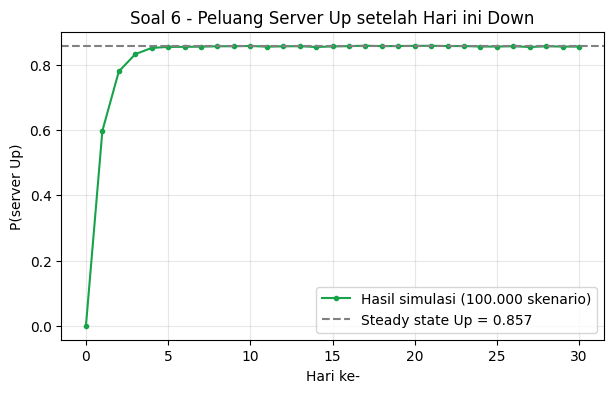

In [ ]:
# Verifikasi dengan simulasi 100.000 skenario, masing-masing 30 hari
skenario, hari = 100_000, 30
riwayat = np.zeros((skenario, hari + 1), dtype=int)
riwayat[:, 0] = 1                              # hari ke-0 = Down (1)
for t in range(1, hari + 1):
    p_down = np.where(riwayat[:, t-1] == 1, P[1, 1], P[0, 1])
    riwayat[:, t] = (np.random.rand(skenario) < p_down).astype(int)

sim_a = ((riwayat[:, 1] == 1) & (riwayat[:, 2] == 1)).mean()
sim_b = (riwayat[:, 2] == 1).mean()
print(f"Simulasi a = {sim_a:.4f} | rumus = {p_a:.4f}")
print(f"Simulasi b = {sim_b:.4f} | rumus = {p_b:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(range(hari + 1), 1 - riwayat.mean(axis=0), marker="o", ms=3, color="#16a34a",label="Hasil simulasi (100.000 skenario)")
plt.axhline(P_besar[0, 0], ls="--", color="gray", label=f"Steady state Up = {P_besar[0,0]:.3f}")
plt.xlabel("Hari ke-")
plt.ylabel("P(server Up)")
plt.title("Soal 6 - Peluang Server Up setelah Hari ini Down")
plt.legend(); plt.grid(alpha=.3)
plt.show()